In [65]:
import pandas as pd
import matplotlib.pyplot as plt
import pickle

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [66]:
df = pd.read_csv('LungCancerDiseasePrediction.csv')

df.head()

,Age,Gender,BMI,Smoking,GeneticRisk,PhysicalActivity,AlcoholIntake,CancerHistory,Diagnosis
0,58,1,16.085313,0,1,8.146251,4.148219,1,1
1,71,0,30.828784,0,1,9.361630,3.519683,0,0
2,48,1,38.785084,0,2,5.135179,4.728368,0,1
3,34,0,30.040296,0,0,9.502792,2.044636,0,0
4,62,1,35.479721,0,0,5.356890,3.309849,0,1


In [67]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               1500 non-null   int64  
 1   Gender            1500 non-null   int64  
 2   BMI               1500 non-null   float64
 3   Smoking           1500 non-null   int64  
 4   GeneticRisk       1500 non-null   int64  
 5   PhysicalActivity  1500 non-null   float64
 6   AlcoholIntake     1500 non-null   float64
 7   CancerHistory     1500 non-null   int64  
 8   Diagnosis         1500 non-null   int64  
dtypes: float64(3), int64(6)
memory usage: 105.6 KB


In [68]:
df.describe()

,Age,Gender,BMI,Smoking,GeneticRisk,PhysicalActivity,AlcoholIntake,CancerHistory,Diagnosis
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,50.320000,0.490667,27.513321,0.269333,0.508667,4.897929,2.417987,0.144000,0.371333
std,17.640968,0.500080,7.230012,0.443761,0.678895,2.866162,1.419318,0.351207,0.483322
min,20.000000,0.000000,15.000291,0.000000,0.000000,0.002410,0.001215,0.000000,0.000000
25%,35.000000,0.000000,21.483134,0.000000,0.000000,2.434609,1.210598,0.000000,0.000000
50%,51.000000,0.000000,27.598494,0.000000,0.000000,4.834316,2.382971,0.000000,0.000000
75%,66.000000,1.000000,33.850837,1.000000,1.000000,7.409896,3.585624,0.000000,1.000000
max,80.000000,1.000000,39.958688,1.000000,2.000000,9.994607,4.987115,1.000000,1.000000


In [69]:
df.isnull().sum()

Age                 0
Gender              0
BMI                 0
Smoking             0
GeneticRisk         0
PhysicalActivity    0
AlcoholIntake       0
CancerHistory       0
Diagnosis           0
dtype: int64

In [70]:
df['Diagnosis'].value_counts()

Diagnosis
0    943
1    557
Name: count, dtype: int64

In [71]:
# Remove duplicate rows
df = df.drop_duplicates()

# Remove rows containing missing values
df = df.dropna()

# Check column names
print(df.columns)

df.head()

Index(['Age', 'Gender', 'BMI', 'Smoking', 'GeneticRisk', 'PhysicalActivity',
       'AlcoholIntake', 'CancerHistory', 'Diagnosis'],
      dtype='object')


,Age,Gender,BMI,Smoking,GeneticRisk,PhysicalActivity,AlcoholIntake,CancerHistory,Diagnosis
0,58,1,16.085313,0,1,8.146251,4.148219,1,1
1,71,0,30.828784,0,1,9.361630,3.519683,0,0
2,48,1,38.785084,0,2,5.135179,4.728368,0,1
3,34,0,30.040296,0,0,9.502792,2.044636,0,0
4,62,1,35.479721,0,0,5.356890,3.309849,0,1


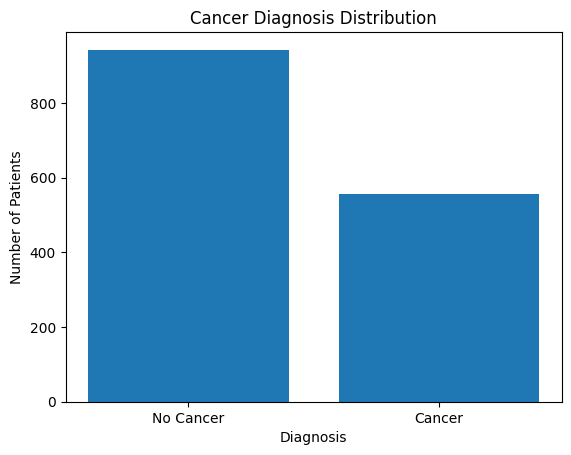

In [72]:
target_counts = df['Diagnosis'].value_counts().reindex([0, 1], fill_value=0)

plt.bar(
    ['No Cancer', 'Cancer'],
    target_counts.values
)

plt.title('Cancer Diagnosis Distribution')
plt.xlabel('Diagnosis')
plt.ylabel('Number of Patients')
plt.show()

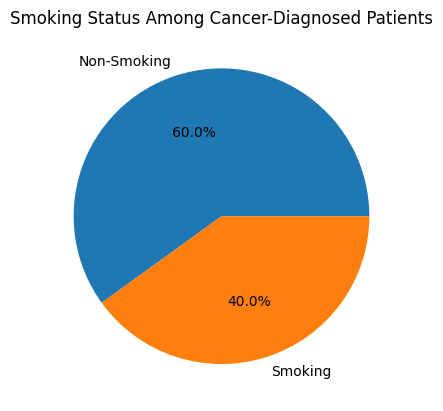

In [73]:
cancer_patients = df[df['Diagnosis'] == 1]

smoking_counts = cancer_patients['Smoking'].value_counts().reindex(
    [0, 1], fill_value=0
)

plt.pie(
    smoking_counts.values,
    labels=['Non-Smoking', 'Smoking'],
    autopct='%1.1f%%'
)

plt.title('Smoking Status Among Cancer-Diagnosed Patients')
plt.show()

In [74]:
X = df.drop('Diagnosis', axis=1)
y = df['Diagnosis']

print("Input features:")
print(X.columns)

print("Target:")
print(y.name)

Input features:
Index(['Age', 'Gender', 'BMI', 'Smoking', 'GeneticRisk', 'PhysicalActivity',
       'AlcoholIntake', 'CancerHistory'],
      dtype='object')
Target:
Diagnosis


In [75]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1200, 8)
Testing data: (300, 8)


In [76]:
model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

,steps,"[('scaler', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


In [77]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy percentage:", accuracy * 100, "%")

Accuracy: 0.8433333333333334
Accuracy percentage: 84.33333333333334 %


In [78]:
print(classification_report(
    y_test,
    y_pred,
    target_names=['No Cancer', 'Cancer'],
    zero_division=0
))

              precision    recall  f1-score   support

   No Cancer       0.87      0.88      0.88       189
      Cancer       0.80      0.77      0.79       111

    accuracy                           0.84       300
   macro avg       0.83      0.83      0.83       300
weighted avg       0.84      0.84      0.84       300



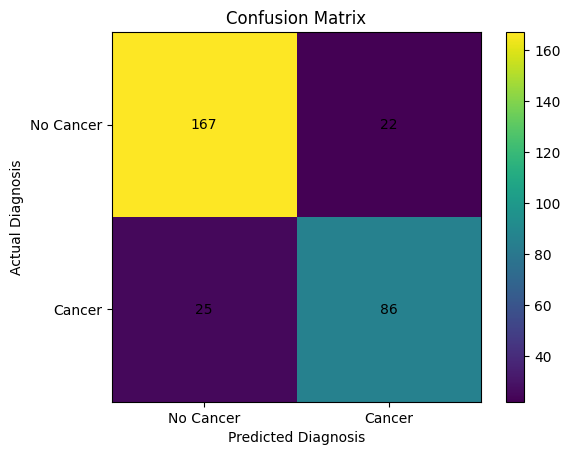

In [79]:
cm = confusion_matrix(y_test, y_pred)

plt.imshow(cm)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Diagnosis')
plt.ylabel('Actual Diagnosis')

plt.xticks([0, 1], ['No Cancer', 'Cancer'])
plt.yticks([0, 1], ['No Cancer', 'Cancer'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.colorbar()
plt.show()

In [80]:
new_patient = pd.DataFrame([{
    'Age': 45,
    'Gender': 1,
    'BMI': 25.5,
    'Smoking': 0,
    'GeneticRisk': 1,
    'PhysicalActivity': 5,
    'AlcoholIntake': 2,
    'CancerHistory': 0
}])

prediction = model.predict(new_patient)[0]
probability = model.predict_proba(new_patient)[0][1]

if prediction == 1:
    print("Predicted class: Cancer")
else:
    print("Predicted class: No Cancer")

print("Model-estimated probability for Cancer:", round(probability * 100, 2), "%")

Predicted class: No Cancer
Model-estimated probability for Cancer: 24.84 %


In [81]:
with open('cancer_model.pkl', 'wb') as file:
    pickle.dump(model, file)